# Практическое занятие №8: Вейвлет-преобразования

## Подготовка окружения

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy import signal
from scipy.fft import dct, idct

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})

## Часть 1. Непрерывное вейвлет-преобразование

### Задание 1.1. Масштаб и частота

1. Выведите центральные частоты (`pywt.central_frequency`) вейвлетов `'mexh'`, `'morl'`, `'cmor1.5-1.0'`, `'gaus1'`.
2. Сформируйте тон 50 Гц длительностью 1 с при $f_s = 1000$ Гц. Задайте 100 частот анализа в геометрической прогрессии от 10 до 200 Гц (`np.geomspace`) и пересчитайте их в масштабы по формуле $a = f_c f_s / f$.
3. Вычислите CWT с вейвлетом `'cmor1.5-1.0'` (`pywt.cwt(x, scales, wavelet, sampling_period=1/fs)`). Постройте зависимость $|W|$, усреднённого по центральной половине записи, от частоты. Совпадает ли максимум с 50 Гц?
4. Повторите для вейвлетов `'mexh'` и `'gaus1'`. Постройте для них также зависимость $|W(a, b)|$ от времени $b$ на масштабе, соответствующем 50 Гц.

mexh центральная частота: 0.25
morl центральная частота: 0.8125
cmor1.5-1.0 центральная частота: 1.0
gaus1 центральная частота: 0.2
cmor1.5-1.0: максимум на 49.72 Гц, отклонение -0.28 Гц
mexh: максимум на 51.25 Гц, отклонение +1.25 Гц
gaus1: максимум на 35.64 Гц, отклонение -14.36 Гц


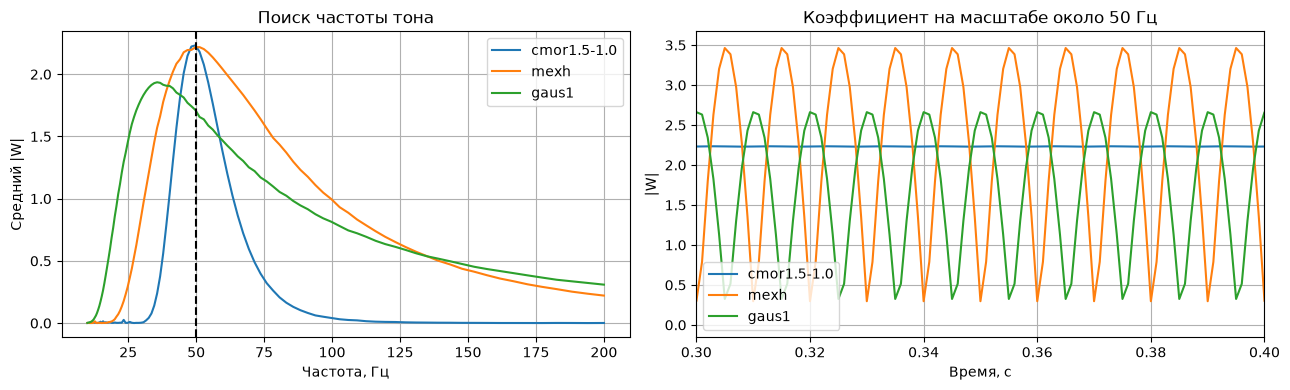

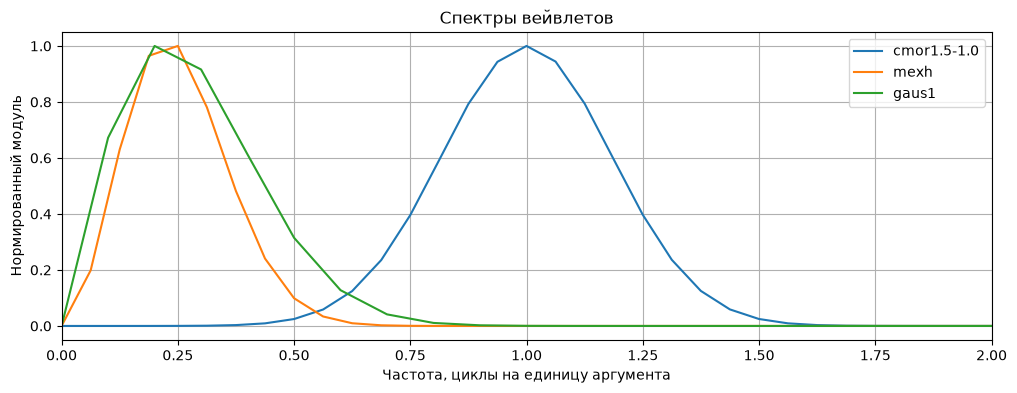

In [2]:
fs = 1000
t = np.arange(fs)/fs
x = np.sin(2*np.pi*50*t)
names = ['mexh', 'morl', 'cmor1.5-1.0', 'gaus1']
for name in names:
    print(name, 'центральная частота:', pywt.central_frequency(name))
freqs = np.geomspace(10, 200, 100)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in ['cmor1.5-1.0', 'mexh', 'gaus1']:
    scales = pywt.central_frequency(name)*fs/freqs
    W, returned_freqs = pywt.cwt(x, scales, name, sampling_period=1/fs)
    mean_amplitude = np.abs(W[:, fs//4:3*fs//4]).mean(axis=1)
    peak = returned_freqs[np.argmax(mean_amplitude)]
    print(f'{name}: максимум на {peak:.2f} Гц, отклонение {peak-50:+.2f} Гц')
    ax[0].plot(returned_freqs, mean_amplitude, label=name)
    idx = np.argmin(np.abs(returned_freqs-50))
    ax[1].plot(t, np.abs(W[idx]), label=name)
ax[0].axvline(50, color='k', ls='--')
ax[0].set(xlabel='Частота, Гц', ylabel='Средний |W|', title='Поиск частоты тона')
ax[1].set(xlabel='Время, с', ylabel='|W|', title='Коэффициент на масштабе около 50 Гц', xlim=(0.3, 0.4))
for a in ax: a.legend()
plt.tight_layout(); plt.show()

# Сравним ширину спектров самих вейвлетов.
for name in ['cmor1.5-1.0', 'mexh', 'gaus1']:
    psi, grid = pywt.ContinuousWavelet(name).wavefun(level=12)
    ff = np.fft.fftfreq(len(grid), grid[1]-grid[0])
    spectrum = np.abs(np.fft.fft(psi))
    positive = ff>=0
    plt.plot(ff[positive], spectrum[positive]/spectrum.max(), label=name)
plt.xlim(0, 2); plt.xlabel('Частота, циклы на единицу аргумента'); plt.ylabel('Нормированный модуль')
plt.title('Спектры вейвлетов'); plt.legend(); plt.show()

**Вопросы:**
- Насколько точно максимум $|W|$ указывает частоту тона для каждого вейвлета?
- Почему для вещественных вейвлетов $|W(a,b)|$ осциллирует во времени, а для комплексного вейвлета Морле – нет?
- Почему для некоторых вейвлетов максимум заметно смещён относительно 50 Гц? (Подсказка: центральная частота – лишь приближённая характеристика широкополосного вейвлета; сравните спектры вейвлетов.)

Морле дал максимум около 49,7 Гц, mexh — 51,3, а gaus1 — 35,6. То есть привязка масштаба к частоте не всегда точная: у широкополосного вейвлета центральная частота лишь ориентир, и нормировка по масштабу тоже влияет.

У вещественных вейвлетов коэффициент меняет знак, поэтому модуль колеблется. У комплексного Морле меняется в основном фаза, а модуль в середине записи почти постоянный. На краях данных уже не хватает, поэтому там результат хуже.

### Задание 1.2. Скалограмма нестационарного сигнала

1. Сформируйте сигнал длительностью 2 с при $f_s = 1000$ Гц: тон 20 Гц амплитудой 0.6 на всей длительности; чирп от 40 до 250 Гц на интервале 0.4–1.6 с (`signal.chirp`); два щелчка (гауссовы импульсы шириной 2 мс) в моменты 0.25 и 1.8 с.
2. Постройте скалограмму $|W(a,b)|$ (вейвлет `'cmor1.5-1.0'`, 150 частот от 4 до 400 Гц) с логарифмической осью частот (`plt.pcolormesh` и `plt.yscale('log')`).
3. Нанесите на скалограмму **конус влияния**: для вейвлета `cmorB-C` на масштабе $a$ краевые эффекты распространяются на расстояние $a\sqrt{B/2}$ отсчётов от краёв записи.
4. Постройте спектрограмму того же сигнала с окном 128 отсчётов и сравните её со скалограммой.

C:\Users\n1\AppData\Local\Temp\ipykernel_50884\612900140.py:24: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.show()


C:\Users\n1\Downloads\dsp-seminars-main\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


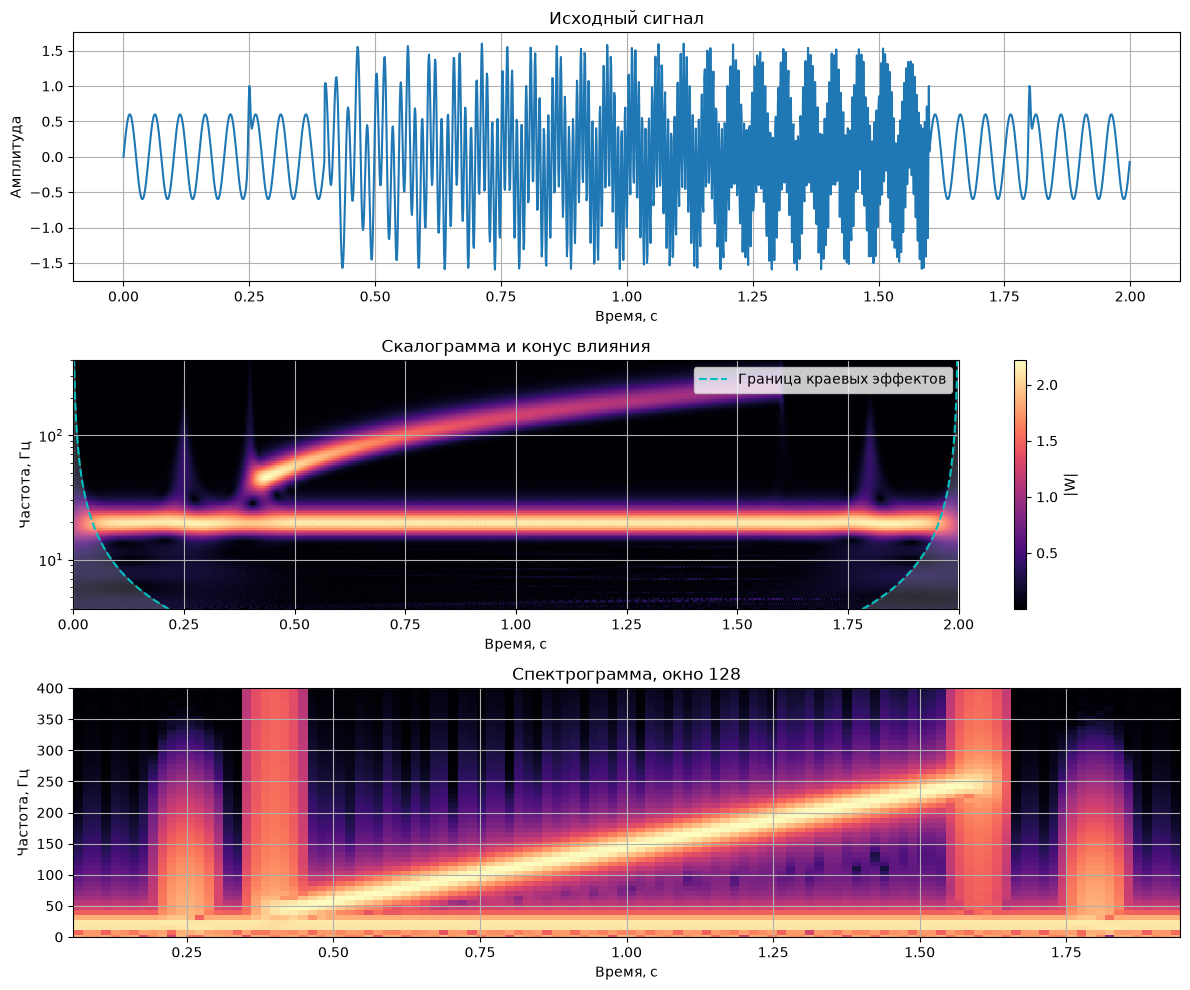

In [3]:
fs = 1000
t = np.arange(2000)/fs
x = 0.6*np.sin(2*np.pi*20*t)
active = (t>=0.4)&(t<=1.6)
x += signal.chirp(t-0.4, f0=40, f1=250, t1=1.2)*active
for center in [0.25, 1.8]:
    x += np.exp(-0.5*((t-center)/0.002)**2)
freqs = np.geomspace(4, 400, 150)
scales = pywt.central_frequency('cmor1.5-1.0')*fs/freqs
W, f_cwt = pywt.cwt(x, scales, 'cmor1.5-1.0', sampling_period=1/fs)
edge = scales*np.sqrt(1.5/2)/fs
fig, ax = plt.subplots(3, 1, figsize=(12, 10))
ax[0].plot(t, x); ax[0].set(xlabel='Время, с', ylabel='Амплитуда', title='Исходный сигнал')
im = ax[1].pcolormesh(t, f_cwt, np.abs(W), shading='auto', cmap='magma')
ax[1].plot(edge, f_cwt, 'c--', label='Граница краевых эффектов')
ax[1].plot(t[-1]-edge, f_cwt, 'c--')
ax[1].fill_betweenx(f_cwt, 0, edge, color='white', alpha=0.18)
ax[1].fill_betweenx(f_cwt, t[-1]-edge, t[-1], color='white', alpha=0.18)
ax[1].set(yscale='log', ylim=(4, 400), xlim=(0, 2), xlabel='Время, с', ylabel='Частота, Гц', title='Скалограмма и конус влияния')
ax[1].legend(); fig.colorbar(im, ax=ax[1], label='|W|')
f_stft, tt, S = signal.spectrogram(x, fs, window='hann', nperseg=128, noverlap=112)
ax[2].pcolormesh(tt, f_stft, 10*np.log10(S+1e-12), shading='auto', cmap='magma')
ax[2].set(ylim=(0, 400), xlabel='Время, с', ylabel='Частота, Гц', title='Спектрограмма, окно 128')
plt.tight_layout(); plt.show()

**Вопросы:**
- Как выглядят на скалограмме тон, чирп и щелчки? Почему щелчки сужаются к высоким частотам?
- Какие детали лучше видны на скалограмме, а какие – на спектрограмме?

Тон у меня дал горизонтальную полосу, чирп — наклонную, а щелчки — почти вертикальные следы. На высоких частотах вейвлет короче, поэтому щелчки там уже. Мне скалограмма удобнее для сочетания низкого тона и коротких событий, а у спектрограммы окно одно для всех частот. Края скалограммы лучше оценивать осторожно: там вейвлет выходит за запись.

### Задание 1.3. Параметр ширины вейвлета Морле

1. Сформируйте сигнал длительностью 2 с при $f_s = 1000$ Гц: сумма тонов 40 и 50 Гц на интервале 0–1 с и два щелчка (одиночные отсчёты амплитуды 20) в моменты 1.50 и 1.52 с.
2. Постройте скалограммы с вейвлетами `'cmorB-1.0'` при $B = 0.5,\ 1.5,\ 5,\ 20$ (частоты 20–150 Гц).
3. Для каждого $B$ определите, различимы ли тоны 40 и 50 Гц и различимы ли два щелчка на частотах около 100 Гц. Для анализа щелчков постройте увеличенный фрагмент скалограммы на интервале 1.45–1.57 с.

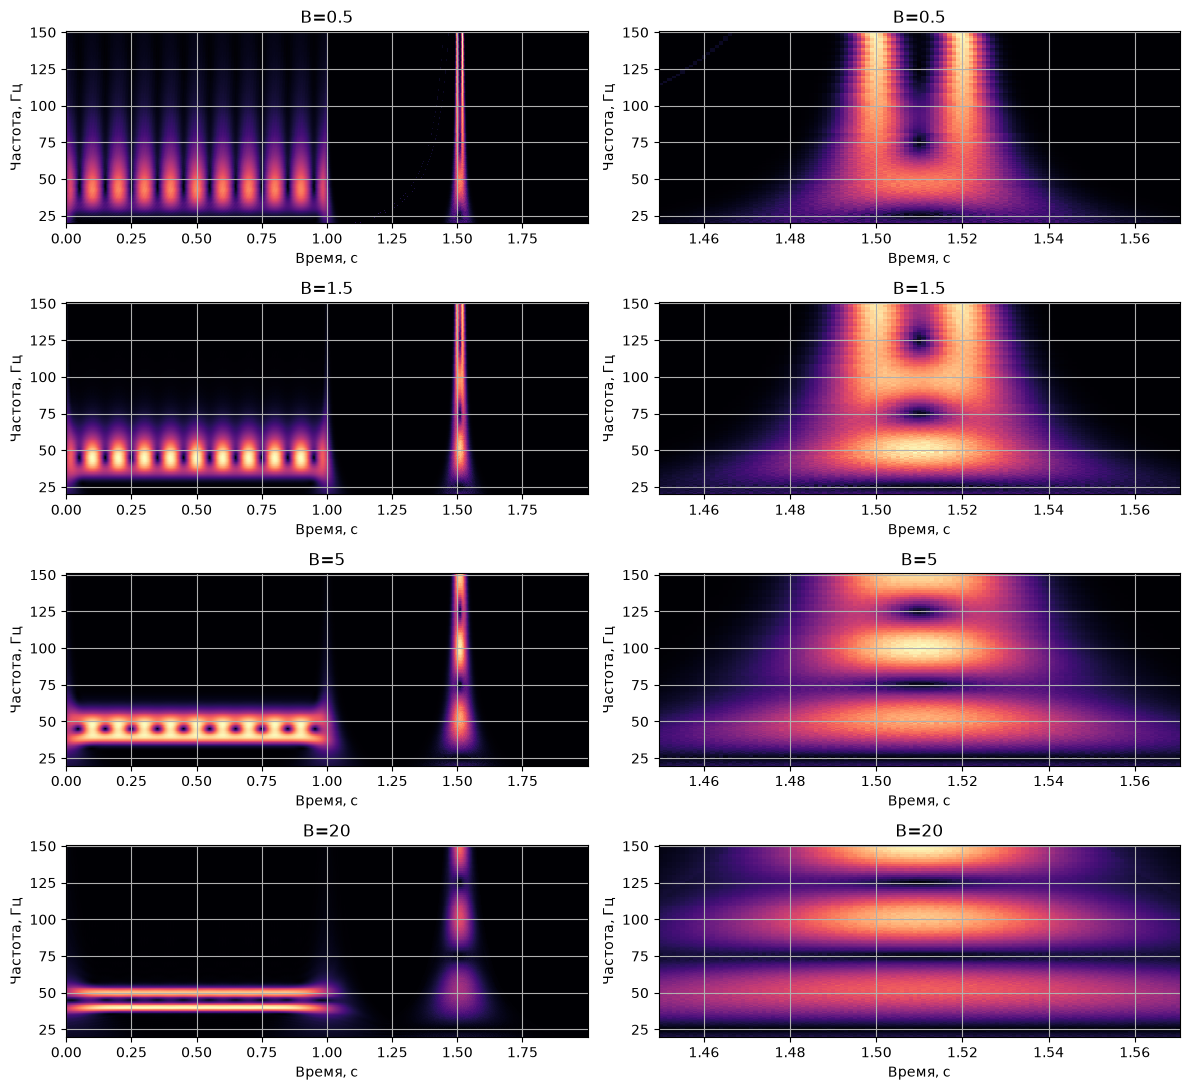

In [4]:
fs = 1000
t = np.arange(2000)/fs
x = (np.sin(2*np.pi*40*t) + np.sin(2*np.pi*50*t))*(t < 1)
x[1500] += 20
x[1520] += 20
freqs = np.geomspace(20, 150, 180)
fig, axes = plt.subplots(4, 2, figsize=(12, 11))
zoom = (t >= 1.45) & (t <= 1.57)
for row, B in enumerate([0.5, 1.5, 5, 20]):
    wavelet = f'cmor{B}-1.0'
    scales = pywt.central_frequency(wavelet)*fs/freqs
    W, f = pywt.cwt(x, scales, wavelet, sampling_period=1/fs)
    axes[row, 0].pcolormesh(t, f, abs(W), shading='auto', cmap='magma')
    axes[row, 1].pcolormesh(t[zoom], f, abs(W[:, zoom]), shading='auto', cmap='magma')
    for ax in axes[row]:
        ax.set(title=f'B={B}', xlabel='Время, с', ylabel='Частота, Гц')
plt.tight_layout()
plt.show()

**Вопросы:**
- При каких $B$ разрешаются тоны? При каких – щелчки? Существует ли $B$, при котором разрешается и то, и другое?
- Как этот результат связан с принципом неопределённости?

По моим графикам тоны разделяются при B=5 и 20. Два щелчка около 100 Гц лучше различаются при B=0,5, а дальше сливаются. Из этих четырёх B одного удачного для обеих задач не нашлось. Ну, причина та же: длинный вейвлет точнее по частоте, короткий — по времени.

## Часть 2. Дискретное вейвлет-преобразование

### Задание 2.1. Преобразование Хаара вручную

1. Допишите функцию `haar_step(a)`, выполняющую один уровень ортонормированного преобразования Хаара: $s_k = (a_{2k} + a_{2k+1})/\sqrt2$, $\;d_k = (a_{2k} - a_{2k+1})/\sqrt2$.
2. Выполните полное разложение сигнала $x = [4,\,2,\,5,\,5,\,1,\,3,\,6,\,6]$ (повторяя шаг для аппроксимации, пока не останется один коэффициент). Сравните с `pywt.wavedec(x, 'haar')`.
3. Напишите обратное преобразование и убедитесь, что сигнал восстанавливается точно.
4. Проверьте равенство Парсеваля: энергия сигнала равна энергии коэффициентов.

In [5]:
def haar_step(a):
    a = np.asarray(a, dtype=float)
    return (a[::2]+a[1::2])/np.sqrt(2), (a[::2]-a[1::2])/np.sqrt(2)

def haar_inverse_step(s, d):
    a = np.empty(2*len(s))
    a[::2] = (s+d)/np.sqrt(2)
    a[1::2] = (s-d)/np.sqrt(2)
    return a

x = np.array([4, 2, 5, 5, 1, 3, 6, 6], dtype=float)
a = x.copy()
details = []
while len(a)>1:
    a, d = haar_step(a)
    details.append(d)
coeffs = [a]+details[::-1]
library = pywt.wavedec(x, 'haar')
for level, (ours, theirs) in enumerate(zip(coeffs, library)):
    print('Коэффициенты', level, ':', ours, 'макс. разница с pywt:', np.max(np.abs(ours-theirs)))
restored = coeffs[0]
for d in coeffs[1:]: restored = haar_inverse_step(restored, d)
print('Восстановленный сигнал:', restored)
print('Макс. ошибка восстановления:', np.max(np.abs(restored-x)))
print('Энергия сигнала:', np.sum(x**2), 'энергия коэффициентов:', sum(np.sum(c**2) for c in coeffs))

Коэффициенты 0 : [11.3137085] макс. разница с pywt: 5.329070518200751e-15
Коэффициенты 1 : [0.] макс. разница с pywt: 0.0
Коэффициенты 2 : [-2. -4.] макс. разница с pywt: 6.661338147750939e-16
Коэффициенты 3 : [ 1.41421356  0.         -1.41421356  0.        ] макс. разница с pywt: 4.440892098500626e-16
Восстановленный сигнал: [4. 2. 5. 5. 1. 3. 6. 6.]
Макс. ошибка восстановления: 2.6645352591003757e-15
Энергия сигнала: 152.0 энергия коэффициентов: 151.99999999999994


**Вопрос:** Почему многие коэффициенты оказались нулевыми? Какие свойства сигнала они отражают?

Детали — это разности соседей. У нас пары 5 и 5, 6 и 6 сразу дают нули. Дальше сравниваются средние более крупных частей, и там тоже могут быть совпадения. Поэтому ровные куски описываются небольшим числом коэффициентов. Я проверил восстановление и энергию — всё совпало до округления.

### Задание 2.2. Один уровень алгоритма Малла

1. Возьмите фильтры вейвлета Добеши db4: `w = pywt.Wavelet('db4')`, фильтры анализа `w.dec_lo`, `w.dec_hi`, синтеза – `w.rec_lo`, `w.rec_hi`.
2. Реализуйте один уровень разложения: свёртка с фильтром анализа (`np.convolve`) и прореживание – взять отсчёты с нечётными индексами (`[1::2]`). Сравните результат с `pywt.dwt(x, 'db4', mode='zero')` для случайного сигнала длиной 64.
3. Реализуйте синтез: вставка нулей между коэффициентами, свёртка с фильтрами синтеза, сложение ветвей. Восстановленный сигнал начинается с отсчёта номер $L - 2$, где $L$ – длина фильтра.
4. Постройте АЧХ фильтров `dec_lo` и `dec_hi` и проверьте, что $|H|^2 + |G|^2 = 2$.

Фильтр анализа НЧ: [-0.0105974   0.03288301  0.03084138 -0.18703481 -0.02798377  0.63088077
  0.71484657  0.23037781]
Фильтр анализа ВЧ: [-0.23037781  0.71484657 -0.63088077 -0.02798377  0.18703481  0.03084138
 -0.03288301 -0.0105974 ]
Макс. ошибки a, d: 4.440892098500626e-16 4.440892098500626e-16
Ошибка синтеза: 8.326672684688674e-16
Макс. отклонение |H|²+|G|² от 2: 1.7763568394002505e-15


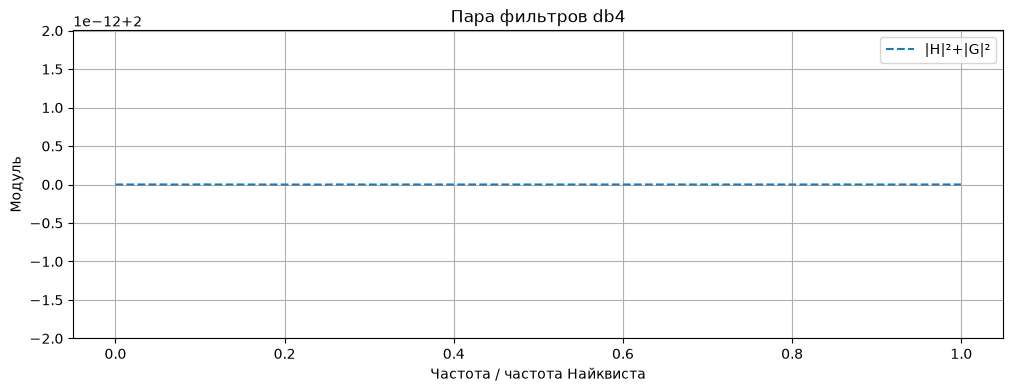

In [6]:
w = pywt.Wavelet('db4')
np.random.seed(0)
x = np.random.randn(64)
a = np.convolve(x, w.dec_lo, mode='full')[1::2]
d = np.convolve(x, w.dec_hi, mode='full')[1::2]
a_ref, d_ref = pywt.dwt(x, 'db4', mode='zero')
print('Фильтр анализа НЧ:', np.array(w.dec_lo))
print('Фильтр анализа ВЧ:', np.array(w.dec_hi))
print('Макс. ошибки a, d:', np.max(np.abs(a-a_ref)), np.max(np.abs(d-d_ref)))

up_a, up_d = np.zeros(2*len(a)), np.zeros(2*len(d))
up_a[::2], up_d[::2] = a, d
combined = np.convolve(up_a, w.rec_lo) + np.convolve(up_d, w.rec_hi)
L = len(w.dec_lo)
x_back = combined[L-2:L-2+len(x)]
print('Ошибка синтеза:', np.max(np.abs(x_back-x)))
omega, H = signal.freqz(w.dec_lo, worN=2048)
_, G = signal.freqz(w.dec_hi, worN=2048)
print('Макс. отклонение |H|²+|G|² от 2:', np.max(np.abs(abs(H)**2+abs(G)**2-2)))
plt.plot(omega/np.pi, abs(H)**2+abs(G)**2, '--', label='|H|²+|G|²')
plt.xlabel('Частота / частота Найквиста'); plt.ylabel('Модуль'); plt.title('Пара фильтров db4')
plt.legend(); plt.show()

**Вопросы:**
- Почему после прореживания информация не теряется, хотя каждая ветвь содержит вдвое меньше отсчётов?
- Почему сложность полного многоуровневого разложения пропорциональна $N$?

Мы оставляем половину отсчётов в каждой ветви, но ветвей две: низкие частоты и детали. Вместе они позволяют восстановить сигнал, что у меня и получилось. На следующих уровнях данных всё меньше: $N+N/2+N/4+\ldots<2N$, поэтому при фиксированной длине фильтра сложность получается линейной.

### Задание 2.3. Многоуровневое разложение и частотные полосы

1. Сформируйте сигнал $x(t) = \sin(2\pi\cdot 10t) + \sin(2\pi\cdot 60t) + \sin(2\pi\cdot 200t)$ длительностью 2.048 с при $f_s = 1000$ Гц.
2. Выполните разложение `pywt.wavedec(x, 'db8', level=6)`. Учтите порядок коэффициентов в списке: $[a_6, d_6, d_5, \dots, d_1]$.
3. Составьте таблицу: уровень, полоса частот ($d_j$ соответствует $[f_s/2^{j+1},\, f_s/2^j]$, $a_J$ – $[0,\, f_s/2^{J+1}]$), доля энергии сигнала в коэффициентах уровня.
4. Восстановите вклад каждого уровня в отдельности (обнулив остальные коэффициенты и применив `pywt.waverec`) и постройте графики.

Уровень   Примерная полоса, Гц       Доля энергии
a6         0.000 –     7.812             2.574%
d6         7.812 –    15.625            30.300%
d5        15.625 –    31.250             0.539%
d4        31.250 –    62.500            19.856%
d3        62.500 –   125.000            13.402%
d2       125.000 –   250.000            29.801%
d1       250.000 –   500.000             3.527%


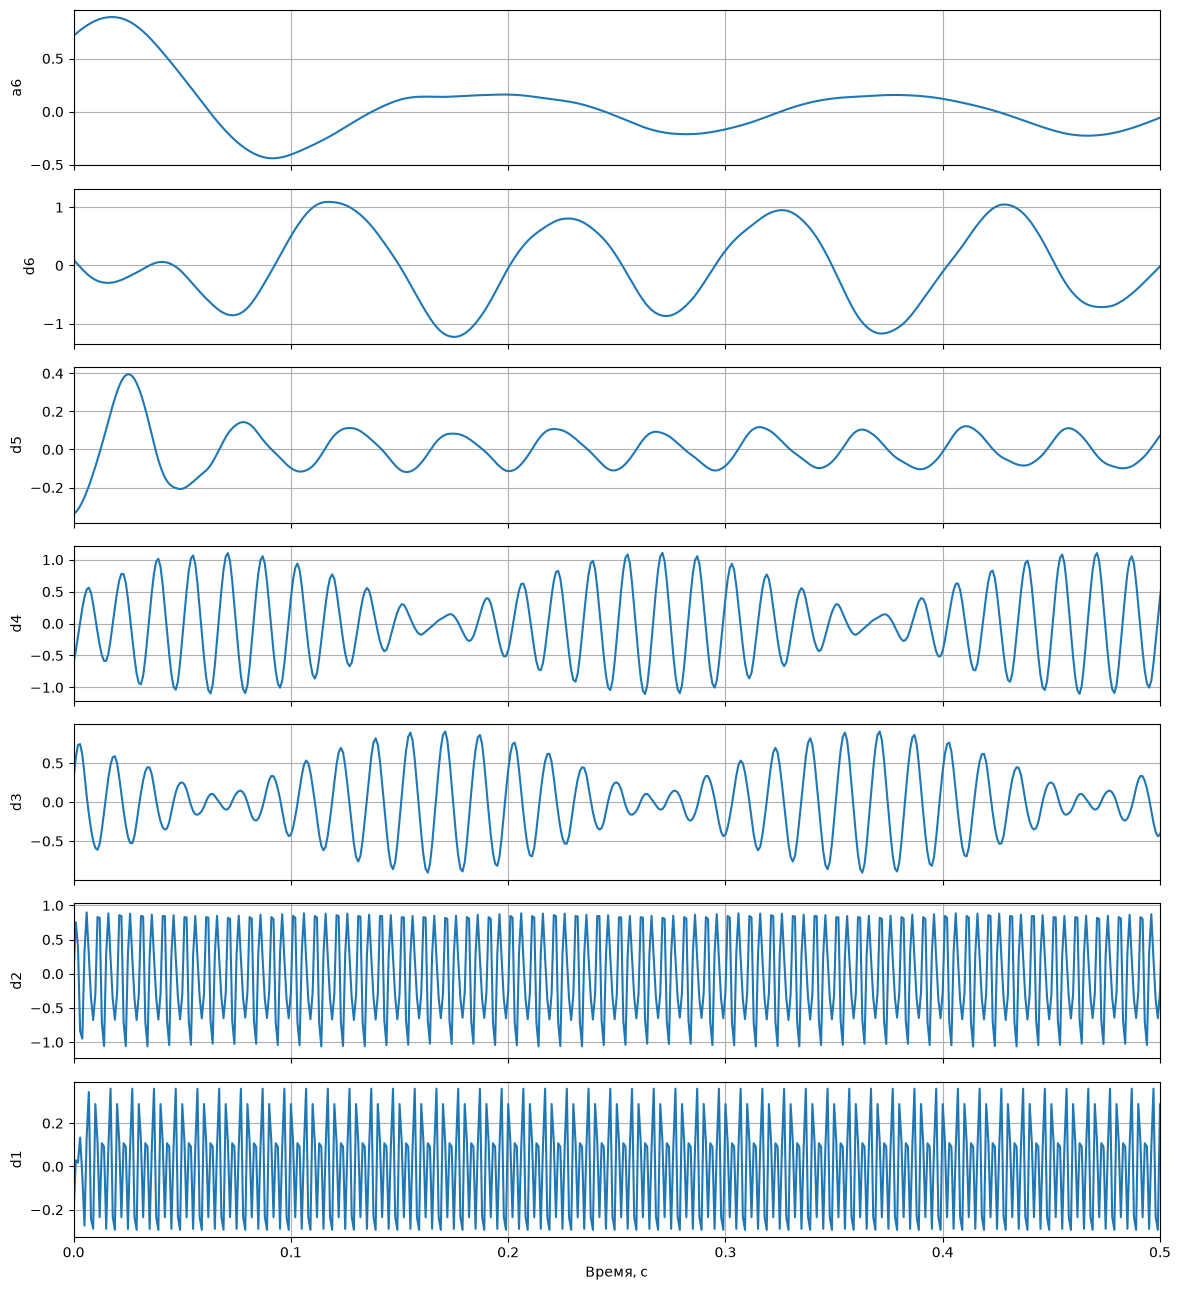

Суммарная доля энергии: 0.9999999999999997


In [7]:
fs = 1000
t = np.arange(2048)/fs
x = sum(np.sin(2*np.pi*f*t) for f in [10, 60, 200])
# Периодическое продолжение даёт ровно N коэффициентов и сохранение энергии.
coeffs = pywt.wavedec(x, 'db8', level=6, mode='periodization')
labels = ['a6']+[f'd{j}' for j in range(6, 0, -1)]
fig, ax = plt.subplots(7, 1, figsize=(12, 13), sharex=True)
print('Уровень   Примерная полоса, Гц       Доля энергии')
for idx, (label, c) in enumerate(zip(labels, coeffs)):
    if idx == 0: low, high = 0, fs/2**7
    else:
        j = 7-idx
        low, high = fs/2**(j+1), fs/2**j
    energy = np.sum(c**2)/np.sum(x**2)
    print(f'{label:5} {low:10.3f} – {high:9.3f}          {100*energy:8.3f}%')
    separated = [np.zeros_like(part) for part in coeffs]
    separated[idx] = c
    contribution = pywt.waverec(separated, 'db8', mode='periodization')[:len(x)]
    ax[idx].plot(t, contribution)
    ax[idx].set(ylabel=label, xlim=(0, 0.5))
ax[-1].set_xlabel('Время, с'); plt.tight_layout(); plt.show()
print('Суммарная доля энергии:', sum(np.sum(c**2) for c in coeffs)/np.sum(x**2))

**Вопросы:**
- В коэффициентах каких уровней оказался каждый из тонов?
- Почему энергия тона 60 Гц распределилась между двумя уровнями?

У меня 10 Гц в основном попали в d6, 60 Гц — в d4 и d3, а 200 Гц — в d2. У 60 Гц рядом граница 62,5 Гц, но фильтры не обрываются резко, поэтому энергия попала в два уровня. Для подсчёта энергии я взял периодическое продолжение, чтобы число коэффициентов совпало с длиной сигнала.

### Задание 2.4. Нулевые моменты

1. Сформируйте кусочно-полиномиальный сигнал из 512 отсчётов на отрезке $[0, 1)$: прямая $2t$ при $t < 0.5$, парабола $1.5 - 4(t - 0.5)^2$ при $t \ge 0.5$ и скачок на $+0.5$ при $t \ge 0.75$.
2. Выполните один уровень DWT (`pywt.dwt(x, wavelet, mode='periodization')`) для вейвлетов `haar`, `db2`, `db3`, `db4`. Постройте детали $d_1$.
3. Для каждого вейвлета подсчитайте число деталей с модулем больше $10^{-6}$. Число нулевых моментов вейвлета можно узнать из `pywt.Wavelet(name).vanishing_moments_psi`.

haar: нулевых моментов 1, ненулевых деталей 256 из 256
db2: нулевых моментов 2, ненулевых деталей 130 из 256
db3: нулевых моментов 3, ненулевых деталей 6 из 256
db4: нулевых моментов 4, ненулевых деталей 12 из 256


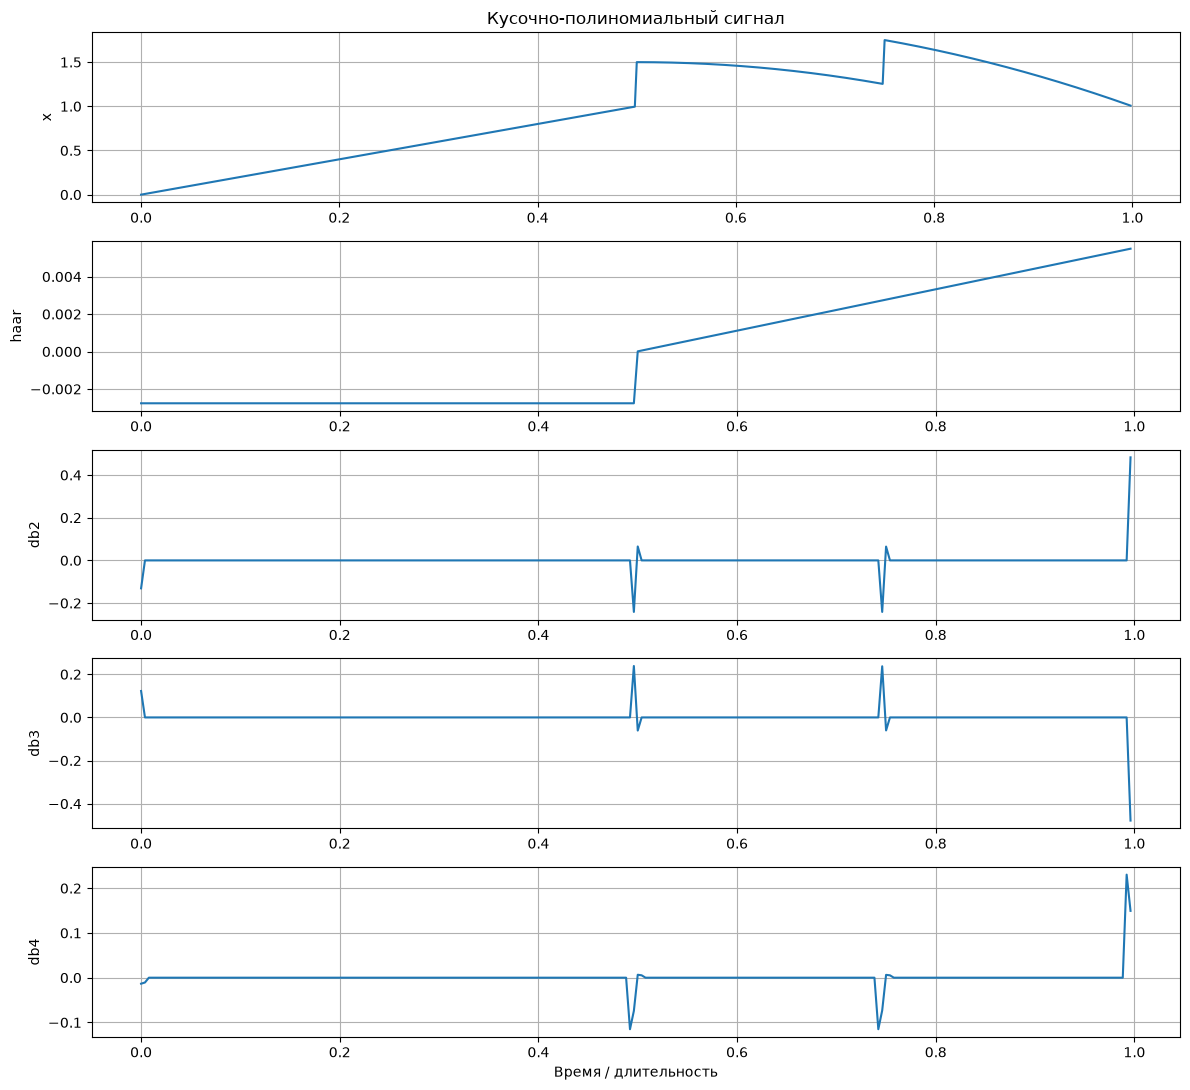

In [8]:
N = 512
n = np.arange(N)/N
x = np.where(n<0.5, 2*n, 1.5-4*(n-0.5)**2) + 0.5*(n>=0.75)
fig, ax = plt.subplots(5, 1, figsize=(12, 11))
ax[0].plot(n, x); ax[0].set(title='Кусочно-полиномиальный сигнал', ylabel='x')
for i, name in enumerate(['haar', 'db2', 'db3', 'db4'], start=1):
    a, d = pywt.dwt(x, name, mode='periodization')
    count = np.count_nonzero(abs(d)>1e-6)
    moments = pywt.Wavelet(name).vanishing_moments_psi
    print(f'{name}: нулевых моментов {moments}, ненулевых деталей {count} из {len(d)}')
    ax[i].plot(np.arange(len(d))*2/N, d)
    ax[i].set(ylabel=name)
ax[-1].set_xlabel('Время / длительность'); plt.tight_layout(); plt.show()

**Вопросы:**
- Как число ненулевых деталей связано с числом нулевых моментов вейвлета?
- Почему ненулевые детали появляются у краёв записи?

Хаар видит даже наклонную прямую, db2 уже убирает её детали, а db3 и db4 почти убирают и параболу. Чем больше нулевых моментов, тем более сложный гладкий полином вейвлет не замечает. Но возле скачка длинный фильтр может дать больше ненулевых коэффициентов. На краях у нас ещё появляется стык конца и начала из-за периодического продолжения.

## Часть 3. Применения

### Задание 3.1. Подавление шума

1. Возьмите тестовые сигналы `pywt.data.demo_signal('Blocks', 1024)` и `pywt.data.demo_signal('Doppler', 1024)`, нормируйте их на стандартное отклонение и добавьте белый шум с σ = 0.25.
2. Реализуйте вейвлет-денойзинг: разложение `wavedec` (5 уровней, `mode='periodization'`), оценка шума $\hat\sigma = \operatorname{median}(|d_1|)/0.6745$, универсальный порог $\lambda = \hat\sigma\sqrt{2\ln N}$, пороговая обработка всех деталей (`pywt.threshold`), обратное преобразование.
3. Сравните мягкий и жёсткий пороги и вейвлеты `haar`, `db4`, `sym8`. Сведите среднеквадратичные ошибки в таблицу.
4. Сравните лучший результат с фильтром Баттерворта 4-го порядка (`signal.butter` + `signal.filtfilt`), подобрав частоту среза так, чтобы ошибка была минимальной.

Blocks вейвлет, порог, оценка шума, RMSE:
haar soft 0.258 0.2006
haar hard 0.258 0.1097
db4 soft 0.268 0.22
db4 hard 0.268 0.1456
sym8 soft 0.263 0.234
sym8 hard 0.263 0.1552
Лучший: haar hard RMSE: 0.1097 Баттерворт: 0.1659
Doppler вейвлет, порог, оценка шума, RMSE:
haar soft 0.265 0.2527
haar hard 0.265 0.1877
db4 soft 0.256 0.159
db4 hard 0.256 0.117
sym8 soft 0.253 0.1401
sym8 hard 0.253 0.086
Лучший: sym8 hard RMSE: 0.086 Баттерворт: 0.128


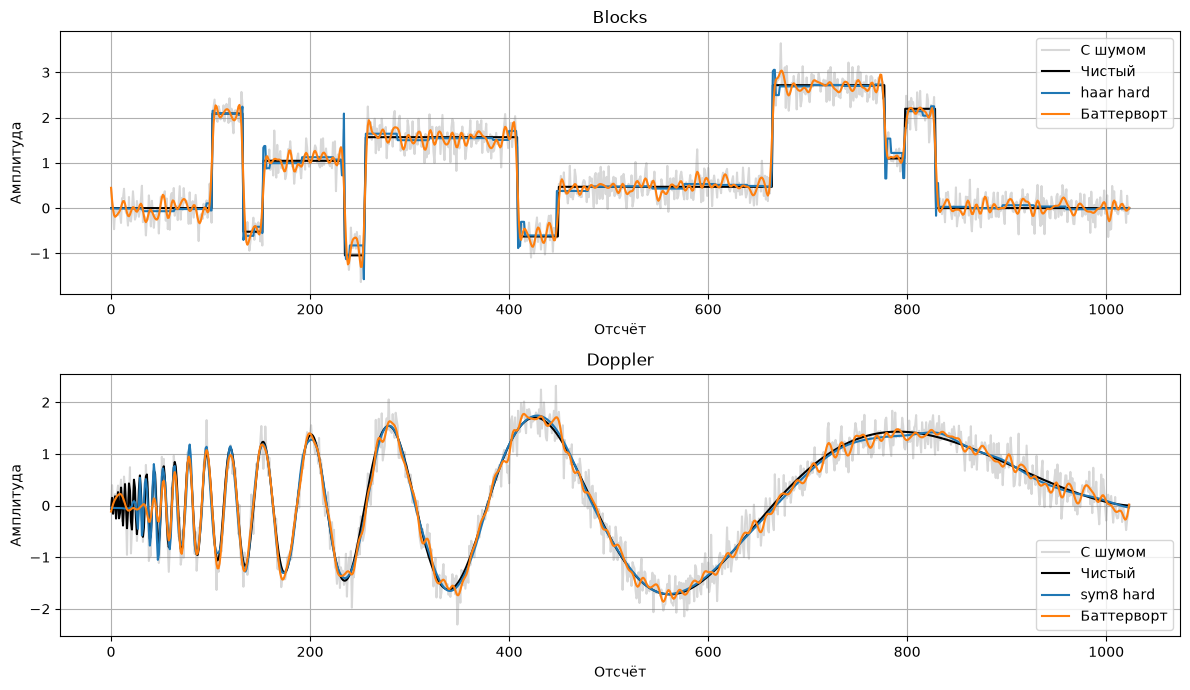

In [9]:
np.random.seed(3)
N = 1024
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, name in zip(axes, ['Blocks', 'Doppler']):
    clean = pywt.data.demo_signal(name, N)
    clean /= np.std(clean)
    noisy = clean + 0.25*np.random.randn(N)
    best_error = np.inf
    print(name, 'вейвлет, порог, оценка шума, RMSE:')
    for wavelet in ['haar', 'db4', 'sym8']:
        coeffs = pywt.wavedec(noisy, wavelet, level=5, mode='periodization')
        sigma = np.median(abs(coeffs[-1]))/0.6745
        threshold = sigma*np.sqrt(2*np.log(N))
        for mode in ['soft', 'hard']:
            filtered = [coeffs[0]] + [pywt.threshold(c, threshold, mode) for c in coeffs[1:]]
            restored = pywt.waverec(filtered, wavelet, mode='periodization')
            error = np.sqrt(np.mean((restored-clean)**2))
            print(wavelet, mode, round(sigma, 3), round(error, 4))
            if error < best_error:
                best_error, best = error, restored
                best_name = wavelet + ' ' + mode
    butter_error = np.inf
    for cutoff in np.arange(0.05, 1, 0.05):
        b, a = signal.butter(4, cutoff)
        restored = signal.filtfilt(b, a, noisy)
        error = np.sqrt(np.mean((restored-clean)**2))
        if error < butter_error:
            butter_error, best_butter = error, restored
    print('Лучший:', best_name, 'RMSE:', round(best_error, 4),
          'Баттерворт:', round(butter_error, 4))
    ax.plot(noisy, color='gray', alpha=0.3, label='С шумом')
    ax.plot(clean, 'k', label='Чистый')
    ax.plot(best, label=best_name)
    ax.plot(best_butter, label='Баттерворт')
    ax.set(title=name, xlabel='Отсчёт', ylabel='Амплитуда')
    ax.legend()
plt.tight_layout()
plt.show()

**Вопросы:**
- Какой вейвлет и какой порог лучше подходят для каждого сигнала? Почему?
- Насколько близка оценка $\hat\sigma$ к истинному уровню шума?
- Почему вейвлет-денойзинг сохраняет фронты лучше линейного фильтра?

Для Blocks у меня выиграл Хаар с жёстким порогом, для Doppler — sym8 с жёстким. Хаар хорошо описывает ступеньки, а sym8 лучше подошёл для плавных колебаний. Оценка шума получилась близкой к заданным 0,25.

Вейвлеты оставляют большие коэффициенты на полезных деталях и убирают мелкие шумовые. Обычный ФНЧ сглаживает и шум, и фронты, поэтому на этих сигналах он проиграл. Срез Баттерворта я подбирал по известному чистому сигналу.

### Задание 3.2. Сжатие сигнала

1. Возьмите сигнал `pywt.data.demo_signal('Piece-Regular', 1024)`.
2. Выполните полное разложение (`wavedec`, вейвлет `db4`, `mode='periodization'`) и сохраните долю $p$ наибольших по модулю коэффициентов, обнулив остальные (удобно использовать `pywt.coeffs_to_array` и `pywt.array_to_coeffs`). Восстановите сигнал.
3. Сделайте то же с коэффициентами ДКП (`dct(x, norm='ortho')`, `idct`).
4. Постройте зависимость относительной ошибки $\|\hat x - x\|/\|x\|$ от $p$ в диапазоне 1–20 % для обоих преобразований (логарифмическая шкала по оси ошибки).
5. Повторите для гладкого сигнала `'HeaviSine'`.

Piece-Regular ошибка при 5%: DWT 0.1068 ДКП 0.1449
HeaviSine ошибка при 5%: DWT 0.0053 ДКП 0.0339


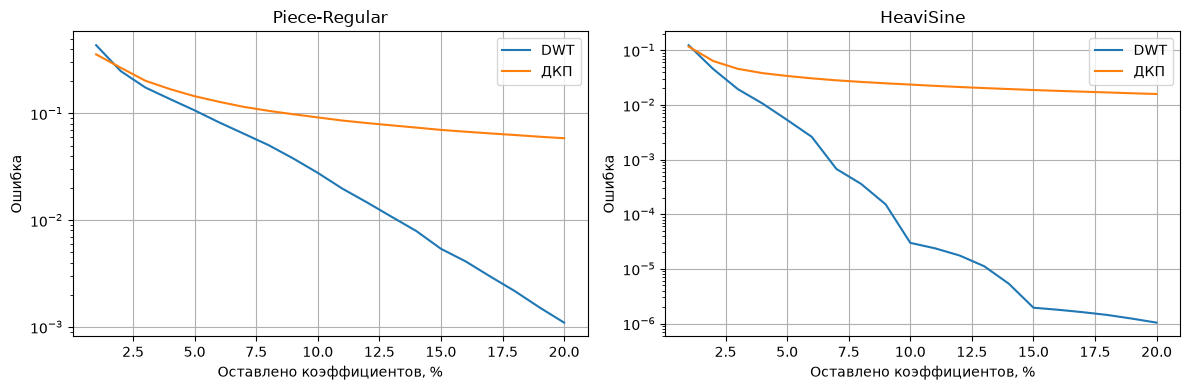

In [10]:
def keep_largest(a, count):
    result = np.zeros_like(a)
    indices = np.argsort(abs(a).ravel())[::-1][:count]
    result.flat[indices] = a.flat[indices]
    return result

fractions = np.arange(1, 21)/100
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ['Piece-Regular', 'HeaviSine']):
    x = pywt.data.demo_signal(name, 1024)
    coeffs = pywt.wavedec(x, 'db4', mode='periodization')
    arr, slices = pywt.coeffs_to_array(coeffs)
    cosine = dct(x, norm='ortho')
    err_w, err_d = [], []
    for p in fractions:
        count = round(p*len(x))
        compressed = keep_largest(arr, count)
        coeffs_w = pywt.array_to_coeffs(compressed, slices, output_format='wavedec')
        x_w = pywt.waverec(coeffs_w, 'db4', mode='periodization')
        x_d = idct(keep_largest(cosine, count), norm='ortho')
        err_w.append(np.linalg.norm(x_w-x)/np.linalg.norm(x))
        err_d.append(np.linalg.norm(x_d-x)/np.linalg.norm(x))
    ax.semilogy(100*fractions, err_w, label='DWT')
    ax.semilogy(100*fractions, err_d, label='ДКП')
    ax.set(title=name, xlabel='Оставлено коэффициентов, %', ylabel='Ошибка')
    ax.legend()
    print(name, 'ошибка при 5%: DWT', round(err_w[4], 4), 'ДКП', round(err_d[4], 4))
plt.tight_layout()
plt.show()

**Вопросы:**
- Для какого сигнала вейвлет-преобразование выигрывает у ДКП, а для какого – нет? Почему?

Для Piece-Regular при 5% коэффициентов я получил ошибку DWT около 0,107, у ДКП — 0,145. Вейвлетам удобнее описывать отдельные куски и скачки. У HeaviSine при 5% DWT тоже выиграло, хотя при очень сильном сжатии ДКП может быть лучше. Тут в сигнале тоже есть скачки, поэтому ожидание «он гладкий, значит ДКП всегда лучше» не сработало.

### Задание 3.3. Сжатие изображения

1. Загрузите изображение `pywt.data.camera()` (512×512, оттенки серого).
2. Выполните двумерное разложение `pywt.wavedec2(img, wavelet, level=3, mode='periodization')`. Изобразите коэффициенты (`pywt.coeffs_to_array`), нормировав каждую субполосу.
3. Сохраните аппроксимацию целиком, а из деталей – наибольшие по модулю коэффициенты так, чтобы всего осталось 1, 2, 5 и 10 % коэффициентов. Восстановите изображение и вычислите PSNR: $10\lg\dfrac{255^2}{\overline{(\hat I - I)^2}}$.
4. Сравните вейвлеты `haar`, `db4` и `bior4.4` (последний близок к CDF 9/7 из JPEG2000).

haar 1.56 %, PSNR: 22.4 дБ
haar 2.0 %, PSNR: 25.92 дБ
haar 5.0 %, PSNR: 30.35 дБ
haar 10.0 %, PSNR: 33.79 дБ
db4 1.56 %, PSNR: 23.22 дБ
db4 2.0 %, PSNR: 26.53 дБ
db4 5.0 %, PSNR: 30.65 дБ
db4 10.0 %, PSNR: 34.06 дБ
bior4.4 1.56 %, PSNR: 23.09 дБ
bior4.4 2.0 %, PSNR: 26.73 дБ
bior4.4 5.0 %, PSNR: 30.99 дБ
bior4.4 10.0 %, PSNR: 34.42 дБ


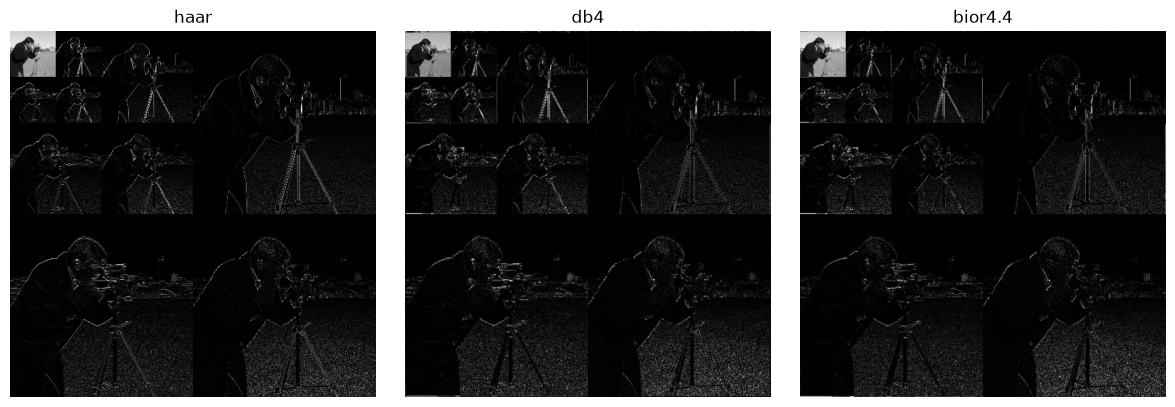

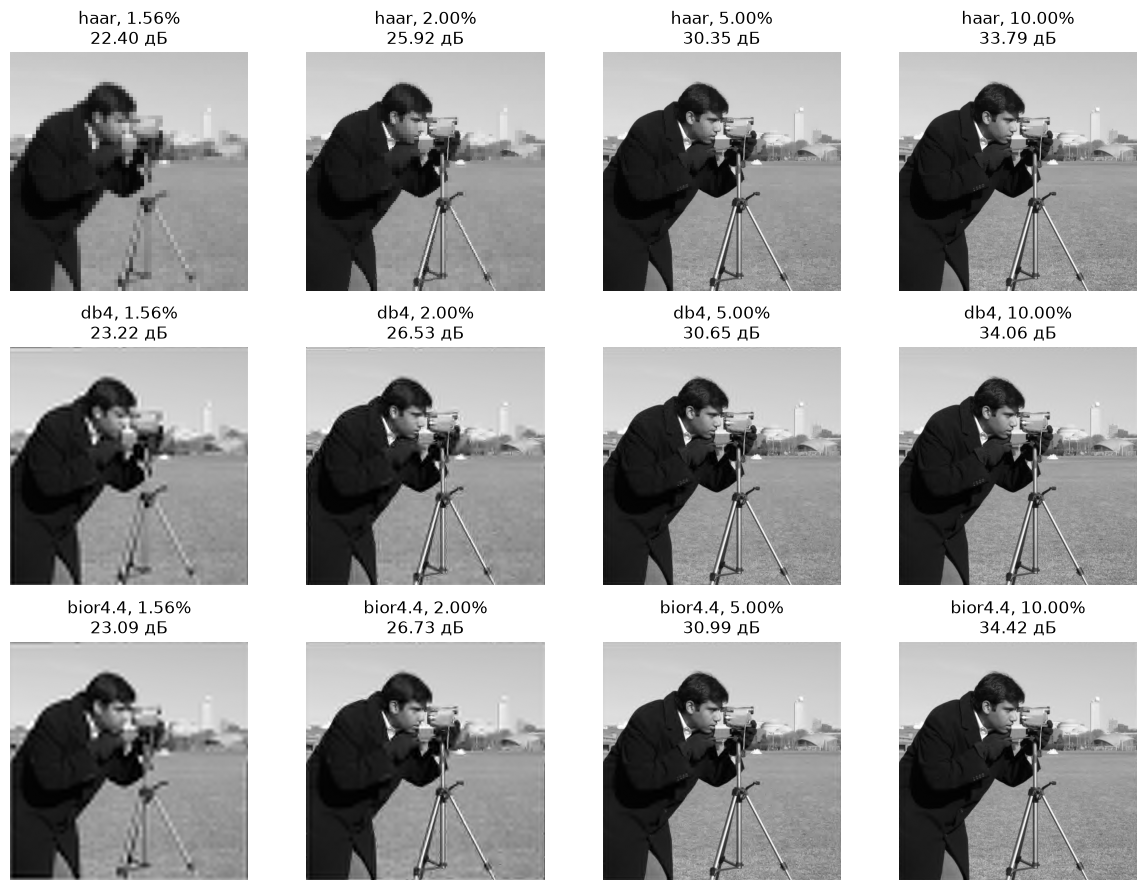

Вся аппроксимация занимает 1.5625%, поэтому ровно 1% здесь не получить.


In [11]:
img = pywt.data.camera().astype(float)
fractions = [0.01, 0.02, 0.05, 0.1]
fig_coeffs, axes_coeffs = plt.subplots(1, 3, figsize=(12, 4))
fig_images, axes_images = plt.subplots(3, 4, figsize=(12, 9))
for row, wavelet in enumerate(['haar', 'db4', 'bior4.4']):
    coeffs = pywt.wavedec2(img, wavelet, level=3, mode='periodization')
    arr, slices = pywt.coeffs_to_array(coeffs)
    normalized = np.zeros_like(arr)
    subbands = [slices[0]]
    for level in slices[1:]:
        subbands.extend(level.values())
    for sl in subbands:
        part = abs(arr[sl])
        normalized[sl] = part/(part.max()+1e-12)
    axes_coeffs[row].imshow(normalized, cmap='gray')
    axes_coeffs[row].set_title(wavelet)
    axes_coeffs[row].axis('off')
    approximation = arr[slices[0]]
    details = arr.copy()
    details[slices[0]] = 0
    for col, p in enumerate(fractions):
        count = max(round(p*arr.size), approximation.size)
        compressed = keep_largest(details, count-approximation.size)
        compressed[slices[0]] = approximation
        back_coeffs = pywt.array_to_coeffs(compressed, slices, output_format='wavedec2')
        back = pywt.waverec2(back_coeffs, wavelet, mode='periodization')
        psnr = 10*np.log10(255**2/np.mean((back-img)**2))
        actual = 100*count/arr.size
        print(wavelet, round(actual, 2), '%, PSNR:', round(psnr, 2), 'дБ')
        axes_images[row, col].imshow(np.clip(back, 0, 255), cmap='gray', vmin=0, vmax=255)
        axes_images[row, col].set_title(f'{wavelet}, {actual:.2f}%\n{psnr:.2f} дБ')
        axes_images[row, col].axis('off')
fig_coeffs.tight_layout()
fig_images.tight_layout()
plt.show()
print('Вся аппроксимация занимает 1.5625%, поэтому ровно 1% здесь не получить.')

**Вопросы:**
- Какие артефакты появляются при сильном сжатии у разных вейвлетов?
- Какой вейвлет даёт наибольший PSNR? Почему в JPEG2000 используют биортогональные вейвлеты?

Хаар у меня даёт заметные квадратики, более гладкие вейвлеты — размывание и колебания возле границ. При 2, 5 и 10% лучший PSNR получился у bior4.4. Биортогональные вейвлеты удобны симметричными фильтрами, поэтому их используют и в JPEG2000.

Ещё момент: вся a3 занимает 1,5625% коэффициентов. Сохранить её целиком и уложиться в 1% нельзя, поэтому в первой колонке у меня фактически 1,5625%. Это пока только обнуление коэффициентов, а не полноценный формат сжатия.

### Задание 3.4. Обработка ЭКГ

1. Загрузите запись ЭКГ `pywt.data.ecg()` (частота дискретизации 360 Гц), вычтите среднее и нормируйте на максимум модуля.
2. Добавьте типичные помехи: дрейф изолинии $0.8\sin(2\pi\cdot 0.3t + 1)$, сетевую наводку $0.15\sin(2\pi\cdot 50t)$ и белый шум с σ = 0.05.
3. Попробуйте найти R-зубцы в зашумлённом сигнале напрямую (`signal.find_peaks` с порогом по высоте и минимальным расстоянием 0.25 с).
4. Выполните разложение `wavedec(y, 'db4', level=7)`. Составьте таблицу частотных полос уровней.
5. **Удаление дрейфа:** обнулите аппроксимацию и восстановите сигнал. Сравните с исходной ЭКГ.
6. **Поиск R-зубцов:** восстановите сигнал только по деталям уровней, в полосы которых попадает энергия QRS-комплекса (примерно 5–45 Гц), и найдите пики квадрата этого сигнала. Вычислите частоту сердечных сокращений.

Уровень     Примерная полоса, Гц
a7            0.000 –    1.406
d7            1.406 –    2.812
d6            2.812 –    5.625
d5            5.625 –   11.250
d4           11.250 –   22.500
d3           22.500 –   45.000
d2           45.000 –   90.000
d1           90.000 –  180.000
Прямой поиск, времена пиков: [0.167 0.528 0.803 1.442]
После DWT, времена R-пиков: [0.528 1.439 2.356]
RR-интервалы, с: [0.911 0.917]
ЧСС по среднему RR: 65.65 уд/мин


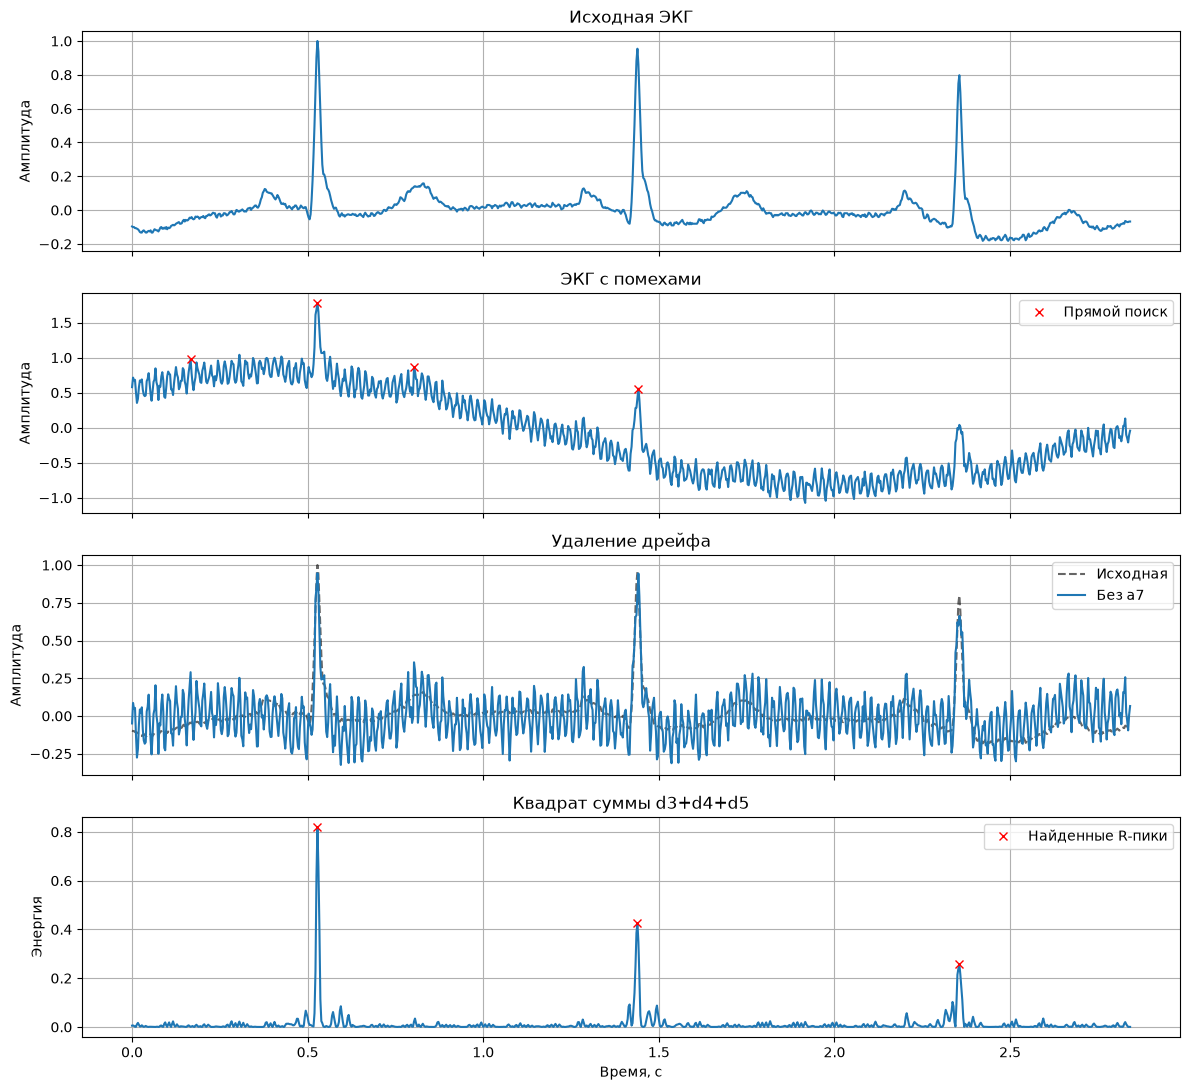

In [12]:
ecg = pywt.data.ecg().astype(float)
ecg -= ecg.mean()
ecg /= np.max(np.abs(ecg))
fs = 360
t = np.arange(len(ecg))/fs
np.random.seed(4)
y = (ecg + 0.8*np.sin(2*np.pi*0.3*t+1)
     + 0.15*np.sin(2*np.pi*50*t) + 0.05*np.random.randn(len(ecg)))
direct_peaks, _ = signal.find_peaks(y, height=0.5, distance=int(0.25*fs))
coeffs = pywt.wavedec(y, 'db4', level=7)
labels = ['a7']+[f'd{j}' for j in range(7, 0, -1)]
print('Уровень     Примерная полоса, Гц')
for idx, label in enumerate(labels):
    if idx == 0: low, high = 0, fs/2**8
    else:
        j = 8-idx
        low, high = fs/2**(j+1), fs/2**j
    print(f'{label:4}       {low:8.3f} – {high:8.3f}')
without_baseline = [np.zeros_like(coeffs[0])]+coeffs[1:]
ecg_no_drift = pywt.waverec(without_baseline, 'db4')[:len(ecg)]
# d3:22.5–45, d4:11.25–22.5, d5:5.625–11.25 Гц.
selected = [c if label in ['d3', 'd4', 'd5'] else np.zeros_like(c)
            for label, c in zip(labels, coeffs)]
qrs = pywt.waverec(selected, 'db4')[:len(ecg)]
energy = qrs**2
r_peaks, properties = signal.find_peaks(energy, height=0.15*energy.max(),
                                        prominence=0.1*energy.max(), distance=int(0.25*fs))
rr = np.diff(r_peaks)/fs
heart_rate = 60/np.mean(rr)
print('Прямой поиск, времена пиков:', np.round(t[direct_peaks], 3))
print('После DWT, времена R-пиков:', np.round(t[r_peaks], 3))
print('RR-интервалы, с:', np.round(rr, 3))
print(f'ЧСС по среднему RR: {heart_rate:.2f} уд/мин')
fig, ax = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
ax[0].plot(t, ecg); ax[0].set(title='Исходная ЭКГ', ylabel='Амплитуда')
ax[1].plot(t, y); ax[1].plot(t[direct_peaks], y[direct_peaks], 'rx', label='Прямой поиск')
ax[1].set(title='ЭКГ с помехами', ylabel='Амплитуда'); ax[1].legend()
ax[2].plot(t, ecg, 'k--', alpha=0.6, label='Исходная'); ax[2].plot(t, ecg_no_drift, label='Без a7')
ax[2].set(title='Удаление дрейфа', ylabel='Амплитуда'); ax[2].legend()
ax[3].plot(t, energy); ax[3].plot(t[r_peaks], energy[r_peaks], 'rx', label='Найденные R-пики')
ax[3].set(title='Квадрат суммы d3+d4+d5', xlabel='Время, с', ylabel='Энергия'); ax[3].legend()
plt.tight_layout(); plt.show()

**Вопросы:**
- Почему прямой поиск пиков в зашумлённом сигнале не работает?
- Какие уровни разложения вы использовали для поиска R-зубцов и почему? Какова частота сердечных сокращений?

Из-за дрейфа вся ЭКГ поднимается и опускается, поэтому фиксированный порог то ловит лишние пики, то пропускает нужные. Я оставил d3, d4 и d5 — примерно 5,6–45 Гц — и искал пики квадрата сигнала. Получилось около 66 ударов в минуту. Запись короткая, так что это грубая оценка по двум интервалам. Обнуление a7 убрало медленный дрейф, но не всю наводку и шум.

## Вывод

Мне вейвлеты пригодились там, где есть короткие события, скачки и другие изменения по времени. И для шума, и для сжатия пришлось подбирать вейвлет и параметры. В общем, я бы сначала сравнил ошибку и графики, а уже потом выбирал метод: одно название преобразования ничего не гарантирует.